In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 77.7 MB/s eta 0:00:00


In [4]:
import shutil

files = ['fast_kan_conv.py', 'kan_conv.py', 'kan.py', 'layers.py', 'utils.py', '__init__.py']

for f in files:

    shutil.copy(f'/content/drive/MyDrive/GKANSU/{f}', f'/content/{f}')

print("All files copied successfully!")

All files copied successfully!


In [5]:
import numpy as np
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torch_geometric.nn as pyg_nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torch_geometric.data import Data, DataLoader as GeometricDataLoader
from skimage.metrics import mean_squared_error
from fast_kan_conv import FastKANConv2DLayer
from kan_conv import KANConv2DLayer

# Spatial-Spectral Attention Module
class SpatialSpectralAttention(nn.Module):
    def __init__(self, channels):
        super(SpatialSpectralAttention, self).__init__()
        self.conv1x1 = nn.Conv2d(channels, channels // 2, kernel_size=1)
        self.conv3x3 = nn.Conv2d(channels // 2, channels, kernel_size=3, padding=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        attn = self.conv1x1(x)
        attn = self.conv3x3(attn)
        attn = self.sigmoid(attn)
        return x * attn

# Improved Graph-KAN Spectral Upsampling Model with Residual Projection
class GKANSU_Improved(nn.Module):
    def __init__(self, in_channels, out_channels, hidden_dim=128, num_gat_layers=3, img_size=(64, 64)):
        """
        :param in_channels: Number of input spectral bands (e.g., 20)
        :param out_channels: Number of output spectral bands (e.g., 200)
        :param hidden_dim: Hidden dimension for the GAT/KAN layers
        :param num_gat_layers: Number of GAT layers to stack
        :param img_size: (height, width) of each image patch
        """
        super(GKANSU_Improved, self).__init__()
        self.img_size = img_size

        # Add a projection layer to match input channels to hidden_dim
        if in_channels != hidden_dim:
            self.input_proj = nn.Linear(in_channels, hidden_dim)
        else:
            self.input_proj = nn.Identity()

        # Graph-Spectral Feature Extraction using multiple GAT layers
        self.gat_layers = nn.ModuleList()
        self.batch_norms = nn.ModuleList()

        # First GAT layer
        self.gat_layers.append(pyg_nn.GATConv(hidden_dim, hidden_dim, heads=4, concat=False))
        self.batch_norms.append(nn.BatchNorm1d(hidden_dim))

        # Additional GAT layers
        for _ in range(num_gat_layers - 1):
            self.gat_layers.append(pyg_nn.GATConv(hidden_dim, hidden_dim, heads=4, concat=False))
            self.batch_norms.append(nn.BatchNorm1d(hidden_dim))

        # Multiple KAN Blocks with Residual Connections
        self.fast_kan1 = FastKANConv2DLayer(hidden_dim, hidden_dim, kernel_size=3, padding=1)
        self.fast_kan2 = FastKANConv2DLayer(hidden_dim, hidden_dim, kernel_size=3, padding=1)

        # Spatial-Spectral Attention
        self.ssa = SpatialSpectralAttention(hidden_dim)

        # Final KAN-based Refinement
        self.final_refinement = KANConv2DLayer(hidden_dim, out_channels, kernel_size=3, padding=1)

        # Non-negativity constraint (using ReLU only)
        self.relu = nn.ReLU()

    def forward(self, x, edge_index):
        """
        :param x: Node features, shape [num_nodes, in_channels]
        :param edge_index: Graph edges (2, E)
        :return: Super-resolved output, shape [batch, out_channels, H, W]
        """
        # Project input features to hidden_dim
        x = self.input_proj(x)

        # Graph-Spectral Learning with GAT layers with skip connections
        for gat_layer, bn in zip(self.gat_layers, self.batch_norms):
            residual = x
            x = gat_layer(x, edge_index)
            x = bn(x)
            x = F.relu(x + residual)

        # Reshape from (num_nodes, hidden_dim) to (batch, hidden_dim, H, W)
        num_nodes = x.shape[0]
        batch_size = num_nodes // (self.img_size[0] * self.img_size[1])
        x = x.view(batch_size, self.img_size[0], self.img_size[1], -1)
        x = x.permute(0, 3, 1, 2)

        # Multiple KAN Blocks with skip connections
        residual = x
        x = self.fast_kan1(x)
        x = F.relu(x + residual)

        residual = x
        x = self.fast_kan2(x)
        x = F.relu(x + residual)

        # Spatial-Spectral Attention
        x = self.ssa(x)

        # Final KAN-based Refinement
        x = self.final_refinement(x)

        # Apply non-negativity constraint
        x = self.relu(x)

        return x



# Data Prep

In [6]:
# Data PRep
# Data Loading Function
def load_npy_files_from_folder(folder_path):
    npy_files = [f for f in os.listdir(folder_path) if f.endswith('.npy')]
    npy_files.sort()
    arrays = [np.load(os.path.join(folder_path, file)) for file in npy_files]
    return np.stack(arrays, axis=0)

# Paths to LR and HR Data
LR_folder_path = '/content/drive/MyDrive/GKANSU/Spectral Datasets/low_res_patches'
HR_folder_path = '/content/drive/MyDrive/GKANSU/Spectral Datasets/high_res_patches'
lr_images = load_npy_files_from_folder(LR_folder_path).astype(np.float32)
hr_images = load_npy_files_from_folder(HR_folder_path).astype(np.float32)

# ----------- NORMALIZATION -----------
# Min-Max Normalization per channel
lr_min = lr_images.min(axis=(0, 1, 2), keepdims=True)
lr_max = lr_images.max(axis=(0, 1, 2), keepdims=True)
hr_min = hr_images.min(axis=(0, 1, 2), keepdims=True)
hr_max = hr_images.max(axis=(0, 1, 2), keepdims=True)
"""
lr_images = (lr_images - lr_min) / (lr_max - lr_min + 1e-8)
hr_images = (hr_images - hr_min) / (hr_max - hr_min + 1e-8)

# Splitting Data
from sklearn.model_selection import train_test_split
trainSL, testSL, trainSH, testSH = train_test_split(lr_images, hr_images, test_size=0.2, random_state=42)
"""

lr_images = (lr_images - lr_min) / (lr_max - lr_min + 1e-8)
hr_images = (hr_images - hr_min) / (hr_max - hr_min + 1e-8)


# ── ADD AUGMENTATION HERE ──────────────────────────────────────
def augment_hsi(lr, hr):
    augmented_lr, augmented_hr = [lr], [hr]
    augmented_lr.append(np.flip(lr, axis=1).copy())
    augmented_hr.append(np.flip(hr, axis=1).copy())
    augmented_lr.append(np.flip(lr, axis=0).copy())
    augmented_hr.append(np.flip(hr, axis=0).copy())
    augmented_lr.append(np.rot90(lr, k=1).copy())
    augmented_hr.append(np.rot90(hr, k=1).copy())
    augmented_lr.append(np.rot90(lr, k=2).copy())
    augmented_hr.append(np.rot90(hr, k=2).copy())
    return augmented_lr, augmented_hr

aug_lr, aug_hr = [], []
for lr, hr in zip(lr_images, hr_images):
    lrs, hrs = augment_hsi(lr, hr)
    aug_lr.extend(lrs)
    aug_hr.extend(hrs)

lr_images = np.array(aug_lr)
hr_images = np.array(aug_hr)
print(f"After augmentation: {len(lr_images)} samples")  # should print 140
# ──────────────────────────────────────────────────────────────

# Splitting Data
from sklearn.model_selection import train_test_split
trainSL, testSL, trainSH, testSH = train_test_split(lr_images, hr_images, test_size=0.2, random_state=42)



# Function to Create Graph Data
def create_graph_from_image(image):
    H, W, C = image.shape
    num_nodes = H * W
    features = image.reshape(num_nodes, C)  # Flatten spatial dims

    edge_index = []
    for i in range(H):
        for j in range(W):
            node = i * W + j
            if i > 0: edge_index.append([node, node - W])
            if i < H - 1: edge_index.append([node, node + W])
            if j > 0: edge_index.append([node, node - 1])
            if j < W - 1: edge_index.append([node, node + 1])
    edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()

    return Data(x=torch.tensor(features, dtype=torch.float), edge_index=edge_index)

# Graph Dataset Class
class HSI_GraphDataset(Dataset):
    def __init__(self, lr_images, hr_images):
        assert len(lr_images) == len(hr_images), "LR and HR images must have the same number of samples"
        self.graphs = [create_graph_from_image(img) for img in lr_images]
        self.hr_images = [torch.tensor(img, dtype=torch.float32).permute(2, 0, 1) for img in hr_images]

    def __len__(self):
        return len(self.graphs)

    def __getitem__(self, idx):
        return self.graphs[idx], self.hr_images[idx]


After augmentation: 180 samples


In [7]:
import torch
print(torch.cuda.is_available())        # Should print True
print(torch.cuda.get_device_name(0))    # Should print T4 or similar

print(torch.cuda.get_device_name(0))  # run this before training

True
Tesla T4
Tesla T4


# Training

In [8]:
"""# Data Loaders
train_dataset = HSI_GraphDataset(trainSL, trainSH)
test_dataset = HSI_GraphDataset(testSL, testSH)
train_loader = GeometricDataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = GeometricDataLoader(test_dataset, batch_size=8, shuffle=True)
# Training for 150 epochs
'''
# Model Training
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

loss_history = []

#epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    loss_history.append(epoch_loss / len(train_loader))
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss_history[-1]:.4f}")

plt.plot(range(1, epochs + 1), loss_history, label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.show()

'''

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Custom SAM Loss Function
def sam_loss(hr, sr, eps=1e-8):
    """ """
    Compute the Spectral Angle Mapper (SAM) loss between two images.
    hr and sr should be tensors of shape [batch, channels, H, W].
    Returns the average spectral angle (in radians) over all pixels.
    """ """
    # Flatten spatial dimensions: shape [batch, channels, num_pixels]
    batch, channels, H, W = hr.shape
    hr_flat = hr.view(batch, channels, -1)
    sr_flat = sr.view(batch, channels, -1)

    # Compute norms along the channel dimension for each pixel
    hr_norm = torch.norm(hr_flat, dim=1, keepdim=True)
    sr_norm = torch.norm(sr_flat, dim=1, keepdim=True)

    # Compute dot product between corresponding spectral vectors
    dot_product = torch.sum(hr_flat * sr_flat, dim=1, keepdim=True)

    # Compute cosine of the spectral angle and clamp for numerical stability
    cos_angle = dot_product / (hr_norm * sr_norm + eps)
    cos_angle = torch.clamp(cos_angle, -1.0, 1.0)

    # Compute the spectral angle (in radians)
    angle = torch.acos(cos_angle)

    # Average the angle over all pixels and batches
    return torch.mean(angle)

# Model Training with Early Stopping and SAM Loss
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
# Use the SAM loss instead of MSELoss
criterion = sam_loss

loss_history = []
patience = 10         # number of epochs to wait for improvement
min_delta = 1e-4      # minimum change to count as an improvement
best_loss = float('inf')
trigger_times = 0

epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch + 1}/{epochs}, SAM Loss: {avg_loss:.4f}")

    # Early Stopping Check
    if best_loss - avg_loss > min_delta:
        best_loss = avg_loss
        trigger_times = 0
    else:
        trigger_times += 1
        print(f"Early stopping trigger count: {trigger_times}/{patience}")
        if trigger_times >= patience:
            print("Loss has stabilized. Stopping training early.")
            break

plt.plot(range(1, len(loss_history) + 1), loss_history, label="SAM Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss (radians)")
plt.title("Training SAM Loss Over Epochs")
plt.legend()
plt.show()
"""

'# Data Loaders\ntrain_dataset = HSI_GraphDataset(trainSL, trainSH)\ntest_dataset = HSI_GraphDataset(testSL, testSH)\ntrain_loader = GeometricDataLoader(train_dataset, batch_size=8, shuffle=True)\ntest_loader = GeometricDataLoader(test_dataset, batch_size=8, shuffle=True)\n# Training for 150 epochs\n\'\'\'\n# Model Training\ndevice = \'cuda\' if torch.cuda.is_available() else \'cpu\'\nmodel = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)\noptimizer = optim.Adam(model.parameters(), lr=1e-4)\ncriterion = nn.MSELoss()\n\nloss_history = []\n\n#epochs = 150\nfor epoch in range(epochs):\n    model.train()\n    epoch_loss = 0\n    for graph_data, hr_imgs in train_loader:\n        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)\n        optimizer.zero_grad()\n        sr_imgs = model(graph_data.x, graph_data.edge_index)\n        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)\n        loss.backward()\n        optimizer.step()\n        epo

/tmp/ipykernel_1086/2529718413.py:4: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  train_loader = GeometricDataLoader(train_dataset, batch_size=8, shuffle=True)
/tmp/ipykernel_1086/2529718413.py:5: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  test_loader = GeometricDataLoader(test_dataset, batch_size=8, shuffle=True)


Epoch 1/150, SAM+MSE Loss: 0.6511
Epoch 2/150, SAM+MSE Loss: 0.4915
Epoch 3/150, SAM+MSE Loss: 0.4102
Epoch 4/150, SAM+MSE Loss: 0.3502
Epoch 5/150, SAM+MSE Loss: 0.2986
Epoch 6/150, SAM+MSE Loss: 0.2653
Epoch 7/150, SAM+MSE Loss: 0.2426
Epoch 8/150, SAM+MSE Loss: 0.2183
Epoch 9/150, SAM+MSE Loss: 0.2104
Epoch 10/150, SAM+MSE Loss: 0.2002
Epoch 11/150, SAM+MSE Loss: 0.1908
Epoch 12/150, SAM+MSE Loss: 0.1955
Early stopping trigger count: 1/10
Epoch 13/150, SAM+MSE Loss: 0.1823
Epoch 14/150, SAM+MSE Loss: 0.1828
Early stopping trigger count: 1/10
Epoch 15/150, SAM+MSE Loss: 0.1744
Epoch 16/150, SAM+MSE Loss: 0.1729
Epoch 17/150, SAM+MSE Loss: 0.1717
Epoch 18/150, SAM+MSE Loss: 0.1642
Epoch 19/150, SAM+MSE Loss: 0.1663
Early stopping trigger count: 1/10
Epoch 20/150, SAM+MSE Loss: 0.1657
Early stopping trigger count: 2/10
Epoch 21/150, SAM+MSE Loss: 0.1638
Epoch 22/150, SAM+MSE Loss: 0.1583
Epoch 23/150, SAM+MSE Loss: 0.1577
Epoch 24/150, SAM+MSE Loss: 0.1560
Epoch 25/150, SAM+MSE Loss: 0

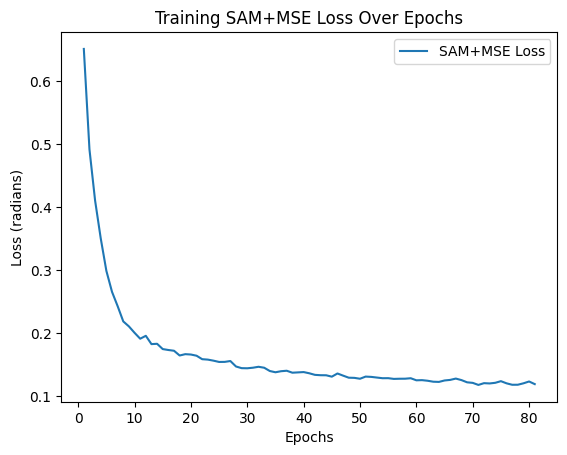

In [9]:
# Data Loaders
train_dataset = HSI_GraphDataset(trainSL, trainSH)
test_dataset = HSI_GraphDataset(testSL, testSH)
train_loader = GeometricDataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = GeometricDataLoader(test_dataset, batch_size=8, shuffle=True)
# Training for 150 epochs
'''
# Model Training
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

loss_history = []

#epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    loss_history.append(epoch_loss / len(train_loader))
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss_history[-1]:.4f}")

plt.plot(range(1, epochs + 1), loss_history, label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.show()

'''

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Custom SAM Loss Function
def sam_loss(hr, sr, eps=1e-8):
    """
    Compute the Spectral Angle Mapper (SAM) loss between two images.
    hr and sr should be tensors of shape [batch, channels, H, W].
    Returns the average spectral angle (in radians) over all pixels.
    """
    batch, channels, H, W = hr.shape
    hr_flat = hr.view(batch, channels, -1)
    sr_flat = sr.view(batch, channels, -1)
    hr_norm = torch.norm(hr_flat, dim=1, keepdim=True)
    sr_norm = torch.norm(sr_flat, dim=1, keepdim=True)
    dot_product = torch.sum(hr_flat * sr_flat, dim=1, keepdim=True)
    cos_angle = dot_product / (hr_norm * sr_norm + eps)
    cos_angle = torch.clamp(cos_angle, -1.0, 1.0)
    angle = torch.acos(cos_angle)
    return torch.mean(angle)

# Combined SAM + MSE Loss
def combined_loss(hr, sr, alpha=0.7, eps=1e-8):
    sam  = sam_loss(hr, sr, eps)
    mse  = F.mse_loss(sr, hr)
    return alpha * sam + (1 - alpha) * mse

# Model Training with Early Stopping and SAM+MSE Loss
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
# Use combined SAM + MSE loss instead of SAM only
criterion = combined_loss

loss_history = []
patience = 10
min_delta = 1e-4
best_loss = float('inf')
trigger_times = 0

epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch + 1}/{epochs}, SAM+MSE Loss: {avg_loss:.4f}")

    if best_loss - avg_loss > min_delta:
        best_loss = avg_loss
        trigger_times = 0
    else:
        trigger_times += 1
        print(f"Early stopping trigger count: {trigger_times}/{patience}")
        if trigger_times >= patience:
            print("Loss has stabilized. Stopping training early.")
            break

plt.plot(range(1, len(loss_history) + 1), loss_history, label="SAM+MSE Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss (radians)")
plt.title("Training SAM+MSE Loss Over Epochs")
plt.legend()
plt.show()

In [10]:
"""# ============================================================
# INSTALL torch_geometric AND DEPENDENCIES
# ============================================================

!pip install torch_geometric
!pip install torch-scatter torch-sparse torch-cluster torch-spline-conv -f https://data.pyg.org/whl/torch-2.0.0+cu118.html

print("✅ torch_geometric installed!")

# Import to verify
import torch_geometric
print(f"✅ torch_geometric version: {torch_geometric.__version__}")"""

'# ============================================================\n# INSTALL torch_geometric AND DEPENDENCIES\n# ============================================================\n\n!pip install torch_geometric\n!pip install torch-scatter torch-sparse torch-cluster torch-spline-conv -f https://data.pyg.org/whl/torch-2.0.0+cu118.html\n\nprint("✅ torch_geometric installed!")\n\n# Import to verify\nimport torch_geometric\nprint(f"✅ torch_geometric version: {torch_geometric.__version__}")'

In [11]:
"""# ── FastKANConv2DLayer inspector ──────────────────────────────
import inspect

layer = model.fast_kan1

# Q1: constructor signature
print("=== CONSTRUCTOR SIGNATURE ===")
print(inspect.signature(layer.__class__.__init__))

# Q2: all parameters and their shapes
print("\n=== ALL NAMED PARAMETERS ===")
for name, param in layer.named_parameters():
    print(f"  {name:40s}  shape={tuple(param.shape)}")

# Q3: all submodules
print("\n=== SUBMODULES ===")
for name, mod in layer.named_modules():
    if name:
        print(f"  {name:40s}  {mod.__class__.__name__}")

# Q4: direct attributes that are tensors
print("\n=== DIRECT TENSOR ATTRIBUTES ===")
for attr in dir(layer):
    if attr.startswith('_'):
        continue
    try:
        val = getattr(layer, attr)
        if isinstance(val, torch.Tensor):
            print(f"  .{attr:38s}  shape={tuple(val.shape)}")
    except:
        pass"""

'# ── FastKANConv2DLayer inspector ──────────────────────────────\nimport inspect\n\nlayer = model.fast_kan1\n\n# Q1: constructor signature\nprint("=== CONSTRUCTOR SIGNATURE ===")\nprint(inspect.signature(layer.__class__.__init__))\n\n# Q2: all parameters and their shapes\nprint("\n=== ALL NAMED PARAMETERS ===")\nfor name, param in layer.named_parameters():\n    print(f"  {name:40s}  shape={tuple(param.shape)}")\n\n# Q3: all submodules\nprint("\n=== SUBMODULES ===")\nfor name, mod in layer.named_modules():\n    if name:\n        print(f"  {name:40s}  {mod.__class__.__name__}")\n\n# Q4: direct attributes that are tensors\nprint("\n=== DIRECT TENSOR ATTRIBUTES ===")\nfor attr in dir(layer):\n    if attr.startswith(\'_\'):\n        continue\n    try:\n        val = getattr(layer, attr)\n        if isinstance(val, torch.Tensor):\n            print(f"  .{attr:38s}  shape={tuple(val.shape)}")\n    except:\n        pass'

In [12]:
"""# Model Training
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

loss_history = []

epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    loss_history.append(epoch_loss / len(train_loader))
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss_history[-1]:.4f}")

plt.plot(range(1, epochs + 1), loss_history, label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.show()"""

'# Model Training\ndevice = \'cuda\' if torch.cuda.is_available() else \'cpu\'\nmodel = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)\noptimizer = optim.Adam(model.parameters(), lr=1e-4)\ncriterion = nn.MSELoss()\n\nloss_history = []\n\nepochs = 150\nfor epoch in range(epochs):\n    model.train()\n    epoch_loss = 0\n    for graph_data, hr_imgs in train_loader:\n        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)\n        optimizer.zero_grad()\n        sr_imgs = model(graph_data.x, graph_data.edge_index)\n        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)\n        loss.backward()\n        optimizer.step()\n        epoch_loss += loss.item()\n    loss_history.append(epoch_loss / len(train_loader))\n    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss_history[-1]:.4f}")\n\nplt.plot(range(1, epochs + 1), loss_history, label="Training Loss")\nplt.xlabel("Epochs")\nplt.ylabel("Loss")\nplt.title("Training Loss Over Epochs")\nplt

In [13]:
"""# Model Training with Early Stopping
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

loss_history = []
patience = 10         # number of epochs to wait for improvement
min_delta = 1e-4      # minimum change to count as an improvement
best_loss = float('inf')
trigger_times = 0

epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {avg_loss:.4f}")

    # Early Stopping Check
    if best_loss - avg_loss > min_delta:
        best_loss = avg_loss
        trigger_times = 0
    else:
        trigger_times += 1
        print(f"Early stopping trigger count: {trigger_times}/{patience}")
        if trigger_times >= patience:
            print("Loss has stabilized. Stopping training early.")
            break

plt.plot(range(1, len(loss_history) + 1), loss_history, label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.show() """

'# Model Training with Early Stopping\ndevice = \'cuda\' if torch.cuda.is_available() else \'cpu\'\nmodel = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)\noptimizer = optim.Adam(model.parameters(), lr=1e-4)\ncriterion = nn.MSELoss()\n\nloss_history = []\npatience = 10         # number of epochs to wait for improvement\nmin_delta = 1e-4      # minimum change to count as an improvement\nbest_loss = float(\'inf\')\ntrigger_times = 0\n\nepochs = 150\nfor epoch in range(epochs):\n    model.train()\n    epoch_loss = 0\n    for graph_data, hr_imgs in train_loader:\n        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)\n        optimizer.zero_grad()\n        sr_imgs = model(graph_data.x, graph_data.edge_index)\n        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)\n        loss.backward()\n        optimizer.step()\n        epoch_loss += loss.item()\n\n    avg_loss = epoch_loss / len(train_loader)\n    loss_history.append(avg_loss)\n 

In [14]:
import torch
torch.cuda.empty_cache()

In [15]:
import torch
import numpy as np
from collections import defaultdict
from skimage.metrics import structural_similarity as ssim

# ── Loss functions ────────────────────────────────────────────
def sam_loss_fn(hr, sr, eps=1e-8):
    batch, channels, H, W = hr.shape
    hr_flat = hr.view(batch, channels, -1)
    sr_flat = sr.view(batch, channels, -1)
    hr_norm = torch.norm(hr_flat, dim=1, keepdim=True)
    sr_norm = torch.norm(sr_flat, dim=1, keepdim=True)
    dot_product = torch.sum(hr_flat * sr_flat, dim=1, keepdim=True)
    cos_angle = dot_product / (hr_norm * sr_norm + eps)
    cos_angle = torch.clamp(cos_angle, -1.0, 1.0)
    return torch.mean(torch.acos(cos_angle))

def loss_fn(sr, hr, alpha=0.7):
    return alpha * sam_loss_fn(hr, sr) + (1 - alpha) * torch.nn.functional.mse_loss(sr, hr)

# ── Full metrics function ─────────────────────────────────────
def evaluate_full_metrics(model, test_loader, device):
    model.eval()
    rmse_vals, sam_vals, psnr_vals, ssim_vals = [], [], [], []
    with torch.no_grad():
        for graph_data, hr_imgs in test_loader:
            graph_data = graph_data.to(device)
            hr_imgs    = hr_imgs.to(device).float()
            sr = model(graph_data.x, graph_data.edge_index)
            sr = sr.view(hr_imgs.shape)
            sr_np = sr.cpu().numpy()
            hr_np = hr_imgs.cpu().numpy()
            for b in range(sr_np.shape[0]):
                s = sr_np[b].transpose(1, 2, 0)
                h = hr_np[b].transpose(1, 2, 0)
                # RMSE
                rmse_vals.append(float(np.sqrt(((s - h)**2).mean())))
                # SAM
                flat_s = s.reshape(-1, s.shape[-1])
                flat_h = h.reshape(-1, h.shape[-1])
                norm_s = np.linalg.norm(flat_s, axis=1, keepdims=True)
                norm_h = np.linalg.norm(flat_h, axis=1, keepdims=True)
                dot    = np.sum(flat_s * flat_h, axis=1, keepdims=True)
                angle  = np.arccos(np.clip(dot / (norm_s * norm_h + 1e-8), -1, 1))
                sam_vals.append(float(np.mean(angle)))
                # PSNR
                mse = np.mean((s - h)**2)
                max_val = max(h.max(), 1.0)
                psnr_vals.append(100.0 if mse == 0 else float(10 * np.log10((max_val**2) / mse)))
                # SSIM
                ssim_per_channel = []
                for c in range(s.shape[-1]):
                    val = ssim(h[:,:,c], s[:,:,c],
                               data_range=h[:,:,c].max() - h[:,:,c].min())
                    ssim_per_channel.append(val)
                ssim_vals.append(float(np.mean(ssim_per_channel)))
    return {
        'RMSE': float(np.mean(rmse_vals)),
        'SAM':  float(np.mean(sam_vals)),
        'PSNR': float(np.mean(psnr_vals)),
        'SSIM': float(np.mean(ssim_vals)),
    }

# ── Taylor Pruner Class ───────────────────────────────────────
class TaylorPrunerKAN:
    def __init__(self, model, prune_ratio=0.30):
        self.model       = model
        self.prune_ratio = prune_ratio
        self.hooks       = []
        self.masks       = {}
        self._saved_acts = {}
        self.scores      = defaultdict(float)
        self.counts      = defaultdict(int)

    def _register_hooks(self):
        def fwd1(mod, inp, out):
            self._saved_acts['fast_kan1'] = out
        def bwd1(mod, grad_in, grad_out):
            act  = self._saved_acts.get('fast_kan1')
            grad = grad_out[0]
            if act is not None and grad is not None:
                per_sample = (grad * act).mean(dim=2).mean(dim=2)
                per_sample = per_sample.abs()
                score      = per_sample.mean(dim=0)
                self.scores['fast_kan1'] += score.detach().cpu()
                self.counts['fast_kan1'] += 1
        def fwd2(mod, inp, out):
            self._saved_acts['fast_kan2'] = out
        def bwd2(mod, grad_in, grad_out):
            act = self._saved_acts.get('fast_kan2')
            grad = grad_out[0]
            if act is not None and grad is not None:
                per_sample = (grad * act).mean(dim=2).mean(dim=2)
                per_sample = per_sample.abs()
                score = per_sample.mean(dim=0)  # CRITICAL: This line was missing
                self.scores['fast_kan2'] += score.detach().cpu()
                self.counts['fast_kan2'] += 1
        self.hooks.append(self.model.fast_kan1.register_forward_hook(fwd1))
        self.hooks.append(self.model.fast_kan1.register_full_backward_hook(bwd1))
        self.hooks.append(self.model.fast_kan2.register_forward_hook(fwd2))
        self.hooks.append(self.model.fast_kan2.register_full_backward_hook(bwd2))

    def _remove_hooks(self):
        for h in self.hooks:
            h.remove()
        self.hooks.clear()

    def collect(self, train_loader, device, n_batches=30):
        self.scores.clear()
        self.counts.clear()
        self._register_hooks()
        self.model.train()
        scaler = torch.amp.GradScaler('cuda')
        print(f"Collecting Taylor scores over {n_batches} batches...")
        for i, (graph_data, hr_imgs) in enumerate(train_loader):
            if i >= n_batches:
                break
            graph_data = graph_data.to(device)
            hr_imgs    = hr_imgs.to(device).float()
            self.model.zero_grad()
            with torch.amp.autocast('cuda'):
                sr   = self.model(graph_data.x, graph_data.edge_index)
                loss = loss_fn(sr.view(hr_imgs.shape), hr_imgs)
            scaler.scale(loss).backward()
            scaler.step(torch.optim.Adam(self.model.parameters(), lr=1e-4))
            scaler.update()
            if (i + 1) % 10 == 0:
                print(f"  Batch {i+1}/{n_batches} done")
        self._remove_hooks()
        print("Collection done.")

    def compute_masks(self):
        for name in ['fast_kan1', 'fast_kan2']:
            if self.counts[name] == 0:
                print(f"WARNING: no scores collected for {name}")
                continue
            avg_score  = self.scores[name] / self.counts[name]
            n_channels = avg_score.shape[0]
            n_prune    = max(1, int(n_channels * self.prune_ratio))
            sorted_idx = torch.argsort(avg_score)
            prune_idx  = sorted_idx[:n_prune]
            keep_mask  = torch.ones(n_channels, dtype=torch.bool)
            keep_mask[prune_idx] = False
            self.masks[name] = keep_mask
            print(f"\n{name}:")
            print(f"  Total channels : {n_channels}")
            print(f"  Pruned         : {n_prune}")
            print(f"  Kept           : {n_channels - n_prune}")
            print(f"  Max score      : {avg_score.max():.6f}")
            print(f"  Min score      : {avg_score.min():.6f}")

    def apply_masks(self):
        for name in ['fast_kan1', 'fast_kan2']:
            if name not in self.masks:
                continue
            mask   = self.masks[name]
            module = getattr(self.model, name)
            def make_hook(m):
                def hook(mod, inp, out):
                    m_dev = m.float().to(out.device).view(1, -1, 1, 1)
                    return out * m_dev
                return hook
            self.hooks.append(module.register_forward_hook(make_hook(mask)))
        print("Masks applied.")

    def remove_masks(self):
        self._remove_hooks()
        print("Masks removed.")


# ============================================================
# STEP 1: Create pruner
# ============================================================
taylor_pruner = TaylorPrunerKAN(model, prune_ratio=0.30)

# ============================================================
# STEP 2: Collect Taylor scores
# ============================================================
taylor_pruner.collect(train_loader, device, n_batches=30)

# ============================================================
# STEP 3: Compute masks
# ============================================================
taylor_pruner.compute_masks()

# ============================================================
# STEP 4: Baseline — captured BEFORE any mask is applied
# ============================================================
print("\n--- STEP 4: Baseline (no pruning) ---")
base_m = evaluate_full_metrics(model, test_loader, device)
print(f"  RMSE={base_m['RMSE']:.4f}  SAM={base_m['SAM']:.4f}  PSNR={base_m['PSNR']:.4f}  SSIM={base_m['SSIM']:.4f}")

# ============================================================
# STEP 5: Apply masks
# ============================================================
taylor_pruner.apply_masks()

# ============================================================
# STEP 6: Evaluate immediately after pruning
# ============================================================
print("\n--- STEP 6: After pruning (before finetune) ---")
prune_m = evaluate_full_metrics(model, test_loader, device)
print(f"  RMSE={prune_m['RMSE']:.4f}  SAM={prune_m['SAM']:.4f}  PSNR={prune_m['PSNR']:.4f}  SSIM={prune_m['SSIM']:.4f}")

# ============================================================
# STEP 7: Finetune 10 epochs with AMP
# ============================================================
print("\n--- STEP 7: Finetuning 10 epochs ---")
optimizer_ft = torch.optim.Adam(model.parameters(), lr=1e-5)
scaler_ft    = torch.amp.GradScaler('cuda')
model.train()
for epoch in range(10):
    ep_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data = graph_data.to(device)
        hr_imgs    = hr_imgs.to(device).float()
        optimizer_ft.zero_grad()
        with torch.amp.autocast('cuda'):
            sr   = model(graph_data.x, graph_data.edge_index)
            loss = loss_fn(sr.view(hr_imgs.shape), hr_imgs)
        scaler_ft.scale(loss).backward()
        scaler_ft.step(optimizer_ft)
        scaler_ft.update()
        ep_loss += loss.item()
    print(f"  Epoch {epoch+1}/10  loss={ep_loss/len(train_loader):.4f}")

# ============================================================
# STEP 8: Evaluate after finetune
# ============================================================
print("\n--- STEP 8: After finetune ---")
ft_m = evaluate_full_metrics(model, test_loader, device)
print(f"  RMSE={ft_m['RMSE']:.4f}  SAM={ft_m['SAM']:.4f}  PSNR={ft_m['PSNR']:.4f}  SSIM={ft_m['SSIM']:.4f}")
taylor_pruner.remove_masks()
# ============================================================
# STEP 9: Final report
# ============================================================
print("\n" + "="*70)
print("           COMPLETE METRICS CHANGE REPORT")
print("="*70)
print(f"{'Metric':<10} {'Baseline':>10} {'After Prune':>12} {'After FT':>10} {'FT vs Base':>12}")
print("-"*70)
for key in ['RMSE', 'SAM', 'PSNR', 'SSIM']:
    delta = ft_m[key] - base_m[key]
    good  = (delta < 0) if key in ['RMSE', 'SAM'] else (delta > 0)
    mark  = '✅' if good else '⚠️'
    print(f"{key:<10} {base_m[key]:>10.4f} {prune_m[key]:>12.4f} {ft_m[key]:>10.4f} {delta:>+12.4f} {mark}")
print("="*70)
print("\nVERDICT:")
for key in ['RMSE', 'SAM', 'PSNR', 'SSIM']:
    delta = ft_m[key] - base_m[key]
    if key in ['RMSE', 'SAM']:
        if delta < 0:
            print(f"  {key} IMPROVED by {abs(delta):.4f} ✅")
        elif abs(delta) < 0.01:
            print(f"  {key} nearly unchanged ({delta:+.4f}) ✅")
        else:
            print(f"  {key} degraded by {abs(delta):.4f} ⚠️")
    else:
        if delta > 0:
            print(f"  {key} IMPROVED by {abs(delta):.4f} ✅")
        elif abs(delta) < 0.01:
            print(f"  {key} nearly unchanged ({delta:+.4f}) ✅")
        else:
            print(f"  {key} degraded by {abs(delta):.4f} ⚠️")
print(f"\n  Channels pruned in fast_kan1 : {(~taylor_pruner.masks['fast_kan1']).sum().item()}")
print(f"  Channels pruned in fast_kan2 : {(~taylor_pruner.masks['fast_kan2']).sum().item()}")
print(f"  Prune ratio used             : {taylor_pruner.prune_ratio*100:.0f}%")

  Batch 10/30 done
Collection done.

fast_kan1:
  Total channels : 128
  Pruned         : 38
  Kept           : 90
  Max score      : 0.012199
  Min score      : 0.000001

fast_kan2:
  Total channels : 128
  Pruned         : 38
  Kept           : 90
  Max score      : 0.015106
  Min score      : 0.000000

--- STEP 4: Baseline (no pruning) ---
  RMSE=0.2715  SAM=0.1655  PSNR=11.3323  SSIM=0.3450
Masks applied.

--- STEP 6: After pruning (before finetune) ---
  RMSE=0.2803  SAM=0.3692  PSNR=11.0559  SSIM=0.2581

--- STEP 7: Finetuning 10 epochs ---
  Epoch 1/10  loss=0.2244
  Epoch 2/10  loss=0.1781
  Epoch 3/10  loss=0.1604
  Epoch 4/10  loss=0.1516
  Epoch 5/10  loss=0.1445
  Epoch 6/10  loss=0.1404
  Epoch 7/10  loss=0.1376
  Epoch 8/10  loss=0.1350
  Epoch 9/10  loss=0.1320
  Epoch 10/10  loss=0.1308

--- STEP 8: After finetune ---
  RMSE=0.2737  SAM=0.1579  PSNR=11.2665  SSIM=0.3198
Masks removed.

           COMPLETE METRICS CHANGE REPORT
Metric       Baseline  After Prune   After 

In [16]:
def evaluate_model(model, test_loader, device):
    model.eval()
    rmse_vals, sam_vals = [], []
    with torch.no_grad():
        for graph_data, hr_imgs in test_loader:
            graph_data = graph_data.to(device)
            hr_imgs    = hr_imgs.to(device).float()
            sr = model(graph_data.x, graph_data.edge_index)
            sr = sr.view(hr_imgs.shape)
            sr_np = sr.cpu().numpy()
            hr_np = hr_imgs.cpu().numpy()
            for b in range(sr_np.shape[0]):
                s = sr_np[b].transpose(1,2,0)
                h = hr_np[b].transpose(1,2,0)
                rmse_vals.append(float(np.sqrt(((s - h)**2).mean())))
                sam_vals.append(float(spectral_angle_mapper(h, s)))
    return float(np.mean(rmse_vals)), float(np.mean(sam_vals))

In [17]:
prune_ratios = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

results = []

for ratio in prune_ratios:
    print(f"\n{'='*60}")
    print(f"  Testing prune_ratio = {ratio*100:.0f}%")
    print(f"{'='*60}")

    pruner = TaylorPrunerKAN(model, prune_ratio=ratio)
    model.load_state_dict(torch.load('/content/drive/MyDrive/GKANSU/model_checkpoint.pth'))
    model.to(device)
    pruner.collect(train_loader, device, n_batches=30)
    pruner.compute_masks()

    # ── FULL 4-metric baseline ──
    base_m = evaluate_full_metrics(model, test_loader, device)

    pruner.apply_masks()

    # ── FULL 4-metric after prune ──
    prune_m = evaluate_full_metrics(model, test_loader, device)

    # ── Finetune ──
    optimizer_ft = torch.optim.Adam(model.parameters(), lr=1e-5)
    scaler_ft    = torch.amp.GradScaler('cuda')
    model.train()
    for epoch in range(10):
        ep_loss = 0
        for graph_data, hr_imgs in train_loader:
            graph_data = graph_data.to(device)
            hr_imgs    = hr_imgs.to(device).float()
            optimizer_ft.zero_grad()
            with torch.amp.autocast('cuda'):
                sr   = model(graph_data.x, graph_data.edge_index)
                loss = loss_fn(sr.view(hr_imgs.shape), hr_imgs)
            scaler_ft.scale(loss).backward()
            scaler_ft.step(optimizer_ft)
            scaler_ft.update()
            ep_loss += loss.item()
        print(f"  Epoch {epoch+1}/10  loss={ep_loss/len(train_loader):.4f}")

    # ── FULL 4-metric after finetune ──
    ft_m = evaluate_full_metrics(model, test_loader, device)

    pruner.remove_masks()

    results.append({
        'ratio'  : ratio,
        'base'   : base_m,
        'pruned' : prune_m,
        'ft'     : ft_m,
    })

# ── Final summary table ───────────────────────────────────────
print("\n\n" + "="*130)
print("                          FULL ABLATION — ALL 4 METRICS")
print("="*130)
print(f"{'Ratio':<8} {'Base SAM':>9} {'Pr SAM':>9} {'FT SAM':>9} {'ΔSAM':>9} {'Base RMSE':>10} {'Pr RMSE':>9} {'FT RMSE':>9} {'ΔRMSE':>9} {'FT PSNR':>9} {'FT SSIM':>9}")
print("-"*130)
for r in results:
    print(
        f"{r['ratio']*100:>5.0f}%  "
        f"  {r['base']['SAM']:>9.4f}"
        f"  {r['pruned']['SAM']:>9.4f}"
        f"  {r['ft']['SAM']:>9.4f}"
        f"  {r['ft']['SAM']-r['base']['SAM']:>+9.4f}"
        f"  {r['base']['RMSE']:>10.4f}"
        f"  {r['pruned']['RMSE']:>9.4f}"
        f"  {r['ft']['RMSE']:>9.4f}"
        f"  {r['ft']['RMSE']-r['base']['RMSE']:>+9.4f}"
        f"  {r['ft']['PSNR']:>9.4f}"
        f"  {r['ft']['SSIM']:>9.4f}"
    )
print("="*130)

# ── Best ratio by SAM ─────────────────────────────────────────
best = min(results, key=lambda x: x['ft']['SAM'])
print(f"\n  Best SAM at prune_ratio = {best['ratio']*100:.0f}%")
print(f"    SAM  = {best['ft']['SAM']:.4f}  (Δ = {best['ft']['SAM']-best['base']['SAM']:+.4f})")
print(f"    RMSE = {best['ft']['RMSE']:.4f}  (Δ = {best['ft']['RMSE']-best['base']['RMSE']:+.4f})")
print(f"    PSNR = {best['ft']['PSNR']:.4f}")
print(f"    SSIM = {best['ft']['SSIM']:.4f}")


  Testing prune_ratio = 30%
  Batch 10/30 done
Collection done.

fast_kan1:
  Total channels : 128
  Pruned         : 38
  Kept           : 90
  Max score      : 0.015190
  Min score      : 0.000001

fast_kan2:
  Total channels : 128
  Pruned         : 38
  Kept           : 90
  Max score      : 0.021347
  Min score      : 0.000000
Masks applied.
  Epoch 1/10  loss=0.3129
  Epoch 2/10  loss=0.2559
  Epoch 3/10  loss=0.2325
  Epoch 4/10  loss=0.2169
  Epoch 5/10  loss=0.2059
  Epoch 6/10  loss=0.1985
  Epoch 7/10  loss=0.1921
  Epoch 8/10  loss=0.1872
  Epoch 9/10  loss=0.1830
  Epoch 10/10  loss=0.1810
Masks removed.

  Testing prune_ratio = 40%
  Batch 10/30 done
Collection done.

fast_kan1:
  Total channels : 128
  Pruned         : 51
  Kept           : 77
  Max score      : 0.016495
  Min score      : 0.000002

fast_kan2:
  Total channels : 128
  Pruned         : 51
  Kept           : 77
  Max score      : 0.021500
  Min score      : 0.000000
Masks applied.
  Epoch 1/10  loss=0.380

In [18]:
import os

# Check common locations
paths = [
    '/content/drive/MyDrive/GKANSU/',
    '/content/drive/MyDrive/',
    '/content/',
]

for folder in paths:
    if os.path.exists(folder):
        files = os.listdir(folder)
        pth_files = [f for f in files if f.endswith('.pth')]
        if pth_files:
            print(f"Found in {folder}:")
            for f in pth_files:
                print(f"  {f}")
        else:
            print(f"{folder} — no .pth files found")
    else:
        print(f"{folder} — folder does not exist")

Found in /content/drive/MyDrive/GKANSU/:
  cnn_best_model.pth
  gkan_usd_pruned.pth
  model_checkpoint.pth
  gkan_wsap_40pct.pth
  gkansu_best_unpruned.pth
  gkan_wsap_pruned.pth
/content/drive/MyDrive/ — no .pth files found
/content/ — no .pth files found


# Visulization

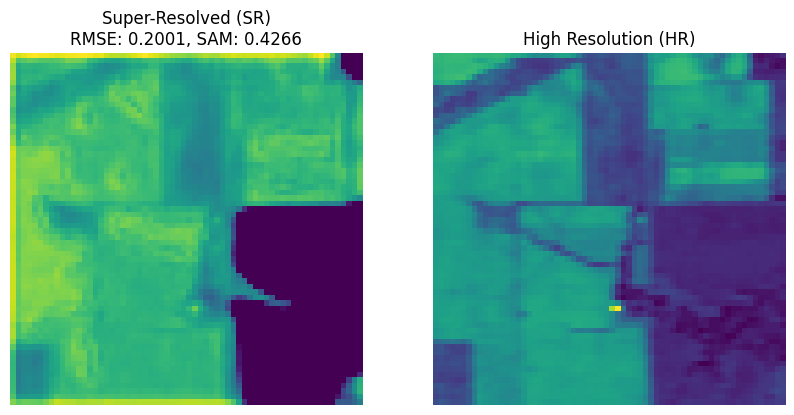

Average RMSE: 0.2001
Average SAM: 0.4266


In [19]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import mean_squared_error

def spectral_angle_mapper(img1, img2):
    """
    Compute the Spectral Angle Mapper (SAM) between two images.
    img1 and img2 should have shape (H, W, C) where C is the number of spectral bands.
    """
    img1_flat = img1.reshape(-1, img1.shape[-1])
    img2_flat = img2.reshape(-1, img2.shape[-1])

    # Normalize to unit vectors
    norm_img1 = np.linalg.norm(img1_flat, axis=1, keepdims=True)
    norm_img2 = np.linalg.norm(img2_flat, axis=1, keepdims=True)

    dot_product = np.sum(img1_flat * img2_flat, axis=1, keepdims=True)
    sam_values = np.arccos(np.clip(dot_product / (norm_img1 * norm_img2 + 1e-8), -1, 1))

    return np.mean(sam_values)  # Return the average SAM value over all pixels

def test_and_visualize(model, test_loader, device='cpu'):
    model.eval()
    sam_values, rmse_values = [], []

    with torch.no_grad():
        for graph_data, hr_img in test_loader:
            graph_data, hr_img = graph_data.to(device), hr_img.to(device)

            # Extract node features and edge index from graph_data
            sr_img = model(graph_data.x, graph_data.edge_index)  # Corrected model input

            # Reshape SR Image to (Batch, Channels, Height, Width)
            sr_img = sr_img.view(hr_img.shape)

            # Move tensors to CPU for visualization
            sr_img_np = sr_img[0].cpu().numpy().transpose(1, 2, 0)  # (H, W, C)
            hr_img_np = hr_img[0].cpu().numpy().transpose(1, 2, 0)  # (H, W, C)

            # Calculate RMSE and SAM
            rmse_value = np.sqrt(mean_squared_error(hr_img_np, sr_img_np))
            sam_value = spectral_angle_mapper(hr_img_np, sr_img_np)

            rmse_values.append(rmse_value)
            sam_values.append(sam_value)

            # Plot images
            fig, axs = plt.subplots(1, 2, figsize=(10, 5))
            axs[0].imshow(sr_img_np[:, :, 127], cmap='viridis')
            axs[0].set_title(f"Super-Resolved (SR)\nRMSE: {rmse_value:.4f}, SAM: {sam_value:.4f}")
            axs[0].axis('off')

            axs[1].imshow(hr_img_np[:, :, 127], cmap='viridis')
            axs[1].set_title("High Resolution (HR)")
            axs[1].axis('off')

            plt.show()
            break  # Display only first batch

    print(f"Average RMSE: {sum(rmse_values) / len(rmse_values):.4f}")
    print(f"Average SAM: {sum(sam_values) / len(sam_values):.4f}")

# Test and visualize results
test_and_visualize(model, test_loader, device)

In [20]:
import requests, os

os.makedirs('datasets', exist_ok=True)

# These are the actual direct file URLs from EHU wiki
# Sometimes they work even when the main page is down
urls = {
    'datasets/Indian_pines_corrected.mat': 'http://www.ehu.eus/ccwintco/uploads/6/67/Indian_pines_corrected.mat',
    'datasets/Indian_pines_gt.mat':        'http://www.ehu.eus/ccwintco/uploads/c/c4/Indian_pines_gt.mat',
}

for path, url in urls.items():
    print(f'Trying {url}...')
    try:
        r = requests.get(url, timeout=30)
        if r.status_code == 200:
            with open(path, 'wb') as f:
                f.write(r.content)
            print(f'  OK — {len(r.content)/1024:.0f} KB saved')
        else:
            print(f'  Failed: status {r.status_code}')
    except Exception as e:
        print(f'  Error: {e}')

Trying http://www.ehu.eus/ccwintco/uploads/6/67/Indian_pines_corrected.mat...
  Failed: status 403
Trying http://www.ehu.eus/ccwintco/uploads/c/c4/Indian_pines_gt.mat...
  Failed: status 403
